# Permissions and file modes

Create three local files and inspect their permission bits through a platform-aware stat command.

A mode comprises owner, group and other permissions. The first digit in this exercise describes owner access. GNU stat and the BSD stat shipped with macOS use different format options, so the example selects the documented form.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
for mode in 600 640 644; do
    file="example-$mode"
    : > "$file"
    chmod "$mode" "$file"
    case $(uname -s) in
        Darwin) stat -f '%Lp' "$file" ;;
        Linux) stat -c '%a' "$file" ;;
        *) printf '%s\n' "Unsupported stat variant" >&2; exit 2 ;;
    esac
done
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [600, 640, 644]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [600, 640, 644]
bash [600, 640, 644]
zsh [600, 640, 644]


## Inspect the outcome

Mode labels are encoded as octal digits and should not be interpreted as a linear access scale. The figure shows the effective read, write and execute bits.

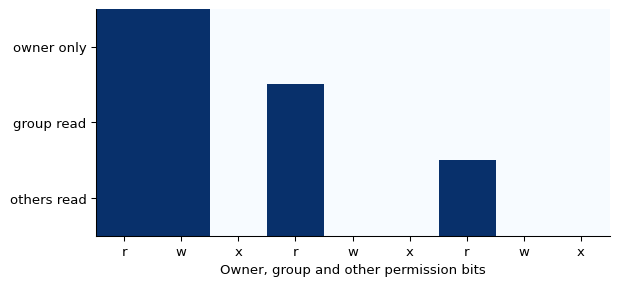

In [3]:
labels = ["owner only", "group read", "others read"]
bits = np.array(
    [
        [int(int(str(mode), 8) & (1 << bit) != 0) for bit in reversed(range(9))]
        for mode in observed
    ]
)
fig, ax = plt.subplots(figsize=(6.4, 2.9), constrained_layout=True)
ax.imshow(bits, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set(
    xticks=range(9),
    xticklabels=list("rwxrwxrwx"),
    yticks=range(3),
    yticklabels=labels,
    xlabel="Owner, group and other permission bits",
)
plt.show()

## Interpreting the result

Mode labels are encoded as octal digits and should not be interpreted as a linear access scale. The figure shows the effective read, write and execute bits.

## Exercise

Set 660 on one file. Identify which class has gained write access.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)